In [ ]:
print("Rows and columns:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()

print("\nStatistical summary:")
display(df.describe(include="all"))

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

Rows and columns: (100, 10)

Column names:
['field_id', 'region', 'crop', 'area_acres', 'soil_ph', 'rainfall_mm', 'fertilizer_kg_acre', 'irrigation_type', 'yield_tons_acre', 'quality_grade']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100 entries, 0 to 99
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   field_id            100 non-null    object 
 1   region              100 non-null    object 
 2   crop                100 non-null    object 
 3   area_acres          100 non-null    float64
 4   soil_ph             100 non-null    float64
 5   rainfall_mm         100 non-null    float64
 6   fertilizer_kg_acre  100 non-null    float64
 7   irrigation_type     100 non-null    object 
 8   yield_tons_acre     100 non-null    float64
 9   quality_grade       100 non-null    object 
dtypes: float64(5), object(5)
memory usage: 7.9+ KB

Statistical summary:


,field_id,region,crop,area_acres,soil_ph,rainfall_mm,fertilizer_kg_acre,irrigation_type,yield_tons_acre,quality_grade
count,100,100,100,100.000000,100.000000,100.000000,100.000000,100,100.000000,100
unique,100,5,5,NaN,NaN,NaN,NaN,4,NaN,3
top,F_001,West,Wheat,NaN,NaN,NaN,NaN,Sprinkler,NaN,Grade B
freq,1,26,25,NaN,NaN,NaN,NaN,34,NaN,40
mean,NaN,NaN,NaN,32.473000,6.507500,633.511000,123.394000,NaN,4.277300,NaN
std,NaN,NaN,NaN,11.231349,0.484475,121.536198,41.485979,NaN,0.997684,NaN
min,NaN,NaN,NaN,10.700000,5.450000,342.300000,50.400000,NaN,1.880000,NaN
25%,NaN,NaN,NaN,22.825000,6.167500,548.775000,90.975000,NaN,3.625000,NaN
50%,NaN,NaN,NaN,31.900000,6.450000,632.450000,127.000000,NaN,4.385000,NaN
75%,NaN,NaN,NaN,42.900000,6.772500,705.400000,158.925000,NaN,4.900000,NaN



Missing values:
field_id              0
region                0
crop                  0
area_acres            0
soil_ph               0
rainfall_mm           0
fertilizer_kg_acre    0
irrigation_type       0
yield_tons_acre       0
quality_grade         0
dtype: int64

Duplicate rows: 0


In [ ]:
from google.colab import files
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

uploaded = files.upload()

filename = next(iter(uploaded))
df = pd.read_csv(filename)

print("Dataset uploaded successfully!")
print("Shape:", df.shape)
display(df.head())

Saving agrinova_farm_data_100x10.csv to agrinova_farm_data_100x10.csv
Dataset uploaded successfully!
Shape: (100, 10)


,field_id,region,crop,area_acres,soil_ph,rainfall_mm,fertilizer_kg_acre,irrigation_type,yield_tons_acre,quality_grade
0,F_001,West,Soybean,49.3,5.85,605.9,106.5,Sprinkler,4.80,Grade C
1,F_002,Central,Wheat,26.0,6.12,584.3,162.4,Rainfed,4.03,Grade B
2,F_003,East,Soybean,42.7,5.99,775.2,108.9,Sprinkler,4.72,Grade A
3,F_004,Central,Corn,41.9,5.91,677.5,174.4,Rainfed,4.65,Grade A
4,F_005,Central,Wheat,16.0,6.72,465.9,135.4,Drip,4.89,Grade A


In [ ]:
clean_df = df.copy()

# Remove extra spaces from column names
clean_df.columns = clean_df.columns.str.strip()

# Remove duplicate rows
clean_df = clean_df.drop_duplicates()

# Clean text columns
text_cols = clean_df.select_dtypes(include="object").columns

for col in text_cols:
    clean_df[col] = clean_df[col].str.strip()

# Convert expected numeric columns
numeric_cols = [
    "area_acres",
    "soil_ph",
    "rainfall_mm",
    "fertilizer_kg_acre",
    "yield_tons_acre"
]

for col in numeric_cols:
    clean_df[col] = pd.to_numeric(clean_df[col], errors="coerce")

# Fill missing numeric values with column medians
for col in numeric_cols:
    clean_df[col] = clean_df[col].fillna(clean_df[col].median())

# Fill missing categorical values with the most frequent value
categorical_cols = clean_df.select_dtypes(include="object").columns

for col in categorical_cols:
    if clean_df[col].isnull().any():
        mode_value = clean_df[col].mode()
        if not mode_value.empty:
            clean_df[col] = clean_df[col].fillna(mode_value.iloc[0])
        else:
            clean_df[col] = clean_df[col].fillna("Unknown")

print("Cleaning completed!")
print("New shape:", clean_df.shape)
print("\nMissing values after cleaning:")
print(clean_df.isnull().sum())
print("\nDuplicates after cleaning:", clean_df.duplicated().sum())

display(clean_df.head())

Cleaning completed!
New shape: (100, 10)

Missing values after cleaning:
field_id              0
region                0
crop                  0
area_acres            0
soil_ph               0
rainfall_mm           0
fertilizer_kg_acre    0
irrigation_type       0
yield_tons_acre       0
quality_grade         0
dtype: int64

Duplicates after cleaning: 0


,field_id,region,crop,area_acres,soil_ph,rainfall_mm,fertilizer_kg_acre,irrigation_type,yield_tons_acre,quality_grade
0,F_001,West,Soybean,49.3,5.85,605.9,106.5,Sprinkler,4.80,Grade C
1,F_002,Central,Wheat,26.0,6.12,584.3,162.4,Rainfed,4.03,Grade B
2,F_003,East,Soybean,42.7,5.99,775.2,108.9,Sprinkler,4.72,Grade A
3,F_004,Central,Corn,41.9,5.91,677.5,174.4,Rainfed,4.65,Grade A
4,F_005,Central,Wheat,16.0,6.72,465.9,135.4,Drip,4.89,Grade A


In [ ]:
print("Numeric column ranges:")
display(clean_df[numeric_cols].agg(["min", "max"]))

# Check possible invalid values
if "area_acres" in clean_df.columns:
    print("Non-positive area:", (clean_df["area_acres"] <= 0).sum())

if "soil_ph" in clean_df.columns:
    print("pH outside 0–14:",
          ((clean_df["soil_ph"] < 0) | (clean_df["soil_ph"] > 14)).sum())

if "rainfall_mm" in clean_df.columns:
    print("Negative rainfall:", (clean_df["rainfall_mm"] < 0).sum())

if "yield_tons_acre" in clean_df.columns:
    print("Negative yield:", (clean_df["yield_tons_acre"] < 0).sum())

Numeric column ranges:


,area_acres,soil_ph,rainfall_mm,fertilizer_kg_acre,yield_tons_acre
min,10.7,5.45,342.3,50.4,1.88
max,49.9,7.62,1040.5,197.1,7.06


Non-positive area: 0
pH outside 0–14: 0
Negative rainfall: 0
Negative yield: 0


In [ ]:
clean_df.to_csv("agrinova_cleaned.csv", index=False)

files.download("agrinova_cleaned.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
print("Average yield:", clean_df["yield_tons_acre"].mean())
print("Highest yield:", clean_df["yield_tons_acre"].max())
print("Lowest yield:", clean_df["yield_tons_acre"].min())

display(clean_df.describe())

Average yield: 4.2773
Highest yield: 7.06
Lowest yield: 1.88


,area_acres,soil_ph,rainfall_mm,fertilizer_kg_acre,yield_tons_acre
count,100.000000,100.000000,100.000000,100.000000,100.000000
mean,32.473000,6.507500,633.511000,123.394000,4.277300
std,11.231349,0.484475,121.536198,41.485979,0.997684
min,10.700000,5.450000,342.300000,50.400000,1.880000
25%,22.825000,6.167500,548.775000,90.975000,3.625000
50%,31.900000,6.450000,632.450000,127.000000,4.385000
75%,42.900000,6.772500,705.400000,158.925000,4.900000
max,49.900000,7.620000,1040.500000,197.100000,7.060000


region
Central    4.557895
East       4.345000
North      3.737778
South      4.324286
West       4.366154
Name: yield_tons_acre, dtype: float64


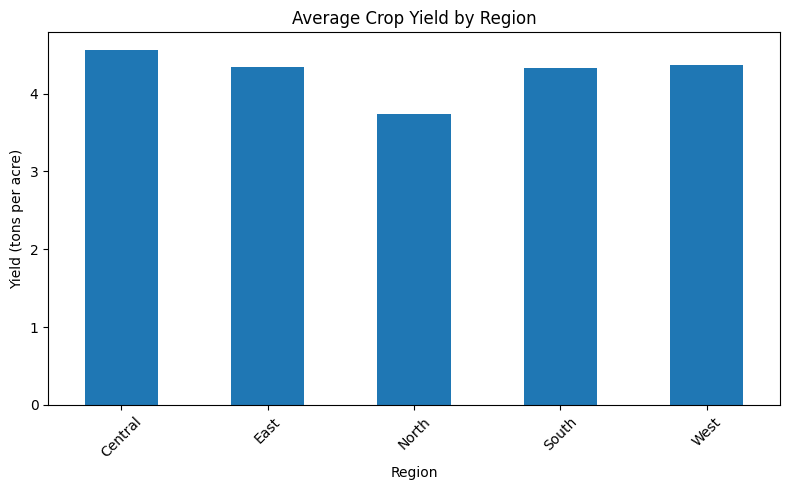

In [ ]:
region_yield = clean_df.groupby("region")["yield_tons_acre"].mean()

print(region_yield)

region_yield.plot(kind="bar", figsize=(8, 5))
plt.title("Average Crop Yield by Region")
plt.xlabel("Region")
plt.ylabel("Yield (tons per acre)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

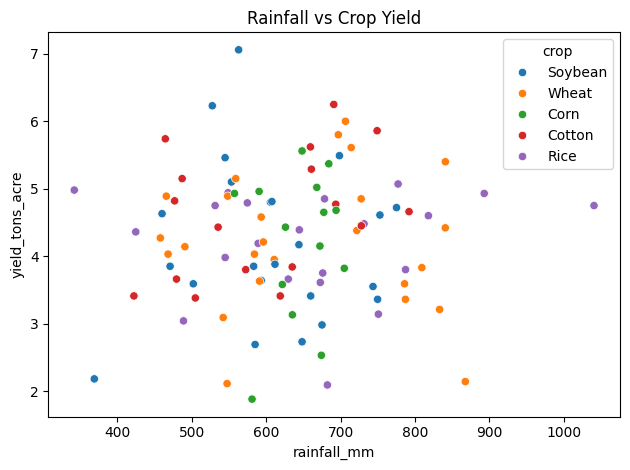

Rainfall-yield correlation: 0.037750895374344666


In [ ]:
sns.scatterplot(
    data=clean_df,
    x="rainfall_mm",
    y="yield_tons_acre",
    hue="crop"
)

plt.title("Rainfall vs Crop Yield")
plt.tight_layout()
plt.show()

print(
    "Rainfall-yield correlation:",
    clean_df["rainfall_mm"].corr(clean_df["yield_tons_acre"])
)

irrigation_type
Sprinkler    4.511765
Flood        4.465455
Drip         4.126333
Rainfed      3.735714
Name: yield_tons_acre, dtype: float64


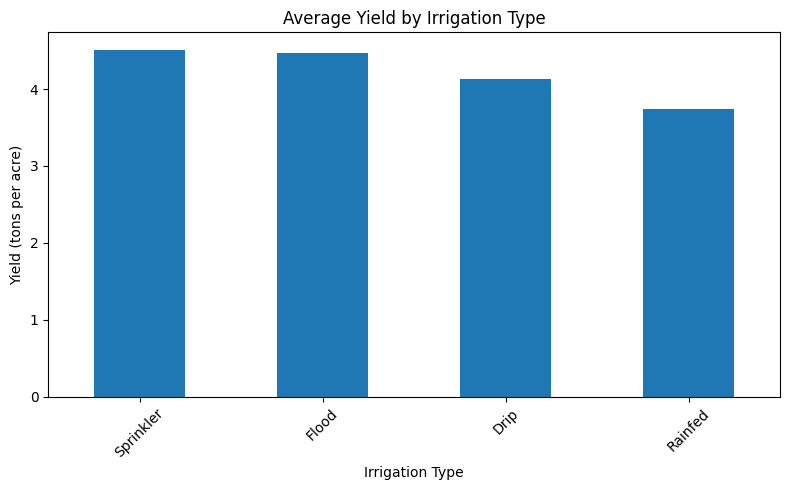

In [ ]:
irrigation_yield = clean_df.groupby(
    "irrigation_type"
)["yield_tons_acre"].mean().sort_values(ascending=False)

print(irrigation_yield)

irrigation_yield.plot(kind="bar", figsize=(8, 5))
plt.title("Average Yield by Irrigation Type")
plt.xlabel("Irrigation Type")
plt.ylabel("Yield (tons per acre)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

crop
Corn       4.192143
Cotton     4.620000
Rice       4.197619
Soybean    4.208261
Wheat      4.222400
Name: yield_tons_acre, dtype: float64


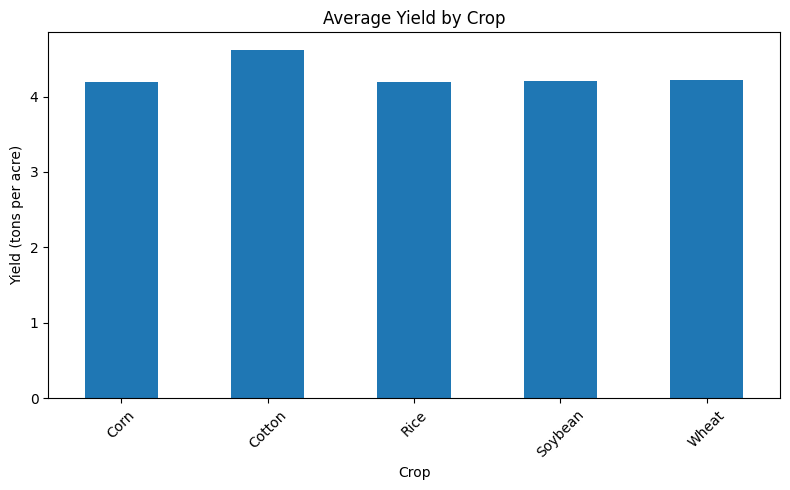

In [ ]:
crop_yield = clean_df.groupby("crop")["yield_tons_acre"].mean()

print(crop_yield)

crop_yield.plot(kind="bar", figsize=(8, 5))
plt.title("Average Yield by Crop")
plt.xlabel("Crop")
plt.ylabel("Yield (tons per acre)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [ ]:
feature_df = clean_df.copy()

# Estimated total production
feature_df["estimated_production_tons"] = (
    feature_df["area_acres"] * feature_df["yield_tons_acre"]
)

# Rainfall category based on this dataset's distribution
feature_df["rainfall_category"] = pd.qcut(
    feature_df["rainfall_mm"],
    q=3,
    labels=["Low", "Medium", "High"],
    duplicates="drop"
)

# Soil pH category
feature_df["soil_ph_category"] = pd.cut(
    feature_df["soil_ph"],
    bins=[-float("inf"), 5.5, 7.5, float("inf")],
    labels=["Acidic", "Near Neutral", "Alkaline"]
)

display(feature_df.head())

,field_id,region,crop,area_acres,soil_ph,rainfall_mm,fertilizer_kg_acre,irrigation_type,yield_tons_acre,quality_grade,estimated_production_tons,rainfall_category,soil_ph_category
0,F_001,West,Soybean,49.3,5.85,605.9,106.5,Sprinkler,4.80,Grade C,236.640,Medium,Near Neutral
1,F_002,Central,Wheat,26.0,6.12,584.3,162.4,Rainfed,4.03,Grade B,104.780,Medium,Near Neutral
2,F_003,East,Soybean,42.7,5.99,775.2,108.9,Sprinkler,4.72,Grade A,201.544,High,Near Neutral
3,F_004,Central,Corn,41.9,5.91,677.5,174.4,Rainfed,4.65,Grade A,194.835,Medium,Near Neutral
4,F_005,Central,Wheat,16.0,6.72,465.9,135.4,Drip,4.89,Grade A,78.240,Low,Near Neutral


In [ ]:
encoded_df = pd.get_dummies(
    feature_df,
    columns=[
        "region",
        "crop",
        "irrigation_type",
        "quality_grade",
        "rainfall_category",
        "soil_ph_category"
    ],
    dtype=int
)

display(encoded_df.head())
print("Encoded shape:", encoded_df.shape)

,field_id,area_acres,soil_ph,rainfall_mm,fertilizer_kg_acre,yield_tons_acre,estimated_production_tons,region_Central,region_East,region_North,...,irrigation_type_Sprinkler,quality_grade_Grade A,quality_grade_Grade B,quality_grade_Grade C,rainfall_category_Low,rainfall_category_Medium,rainfall_category_High,soil_ph_category_Acidic,soil_ph_category_Near Neutral,soil_ph_category_Alkaline
0,F_001,49.3,5.85,605.9,106.5,4.80,236.640,0,0,0,...,1,0,0,1,0,1,0,0,1,0
1,F_002,26.0,6.12,584.3,162.4,4.03,104.780,1,0,0,...,0,0,1,0,0,1,0,0,1,0
2,F_003,42.7,5.99,775.2,108.9,4.72,201.544,0,1,0,...,1,1,0,0,0,0,1,0,1,0
3,F_004,41.9,5.91,677.5,174.4,4.65,194.835,1,0,0,...,0,1,0,0,0,1,0,0,1,0
4,F_005,16.0,6.72,465.9,135.4,4.89,78.240,1,0,0,...,0,1,0,0,1,0,0,0,1,0


Encoded shape: (100, 30)


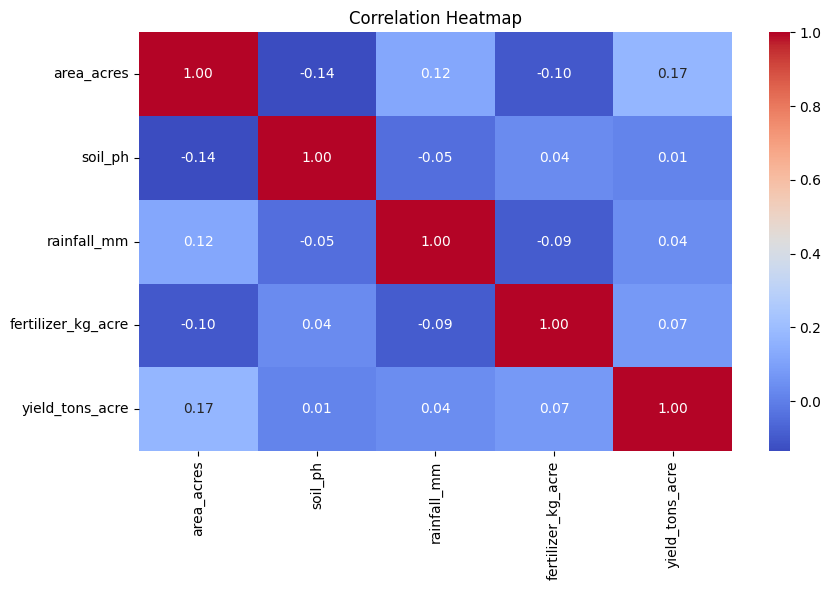

In [ ]:
numeric_df = clean_df.select_dtypes(include="number")

plt.figure(figsize=(9, 6))
sns.heatmap(
    numeric_df.corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()

In [ ]:
# Save CSV files
clean_df.to_csv("agrinova_cleaned.csv", index=False)
feature_df.to_csv("agrinova_feature_engineered.csv", index=False)
encoded_df.to_csv("agrinova_encoded.csv", index=False)

# Create Excel workbook with multiple sheets
with pd.ExcelWriter("agrinova_eda_results.xlsx", engine="openpyxl") as writer:
    clean_df.to_excel(writer, sheet_name="Cleaned_Data", index=False)
    feature_df.to_excel(writer, sheet_name="Feature_Engineered", index=False)
    encoded_df.to_excel(writer, sheet_name="Encoded_Data", index=False)

    clean_df.describe().to_excel(writer, sheet_name="Statistics")

    clean_df.groupby("region")["yield_tons_acre"].mean().to_frame(
        "Average_Yield"
    ).to_excel(writer, sheet_name="Region_Analysis")

    clean_df.groupby("irrigation_type")["yield_tons_acre"].mean().to_frame(
        "Average_Yield"
    ).to_excel(writer, sheet_name="Irrigation_Analysis")

    clean_df.groupby("crop")["yield_tons_acre"].mean().to_frame(
        "Average_Yield"
    ).to_excel(writer, sheet_name="Crop_Analysis")

print("All files created successfully!")

All files created successfully!


In [ ]:
files.download("agrinova_cleaned.csv")
files.download("agrinova_feature_engineered.csv")
files.download("agrinova_encoded.csv")
files.download("agrinova_eda_results.xlsx")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>